In [1]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [2]:
np.random.seed(452533)

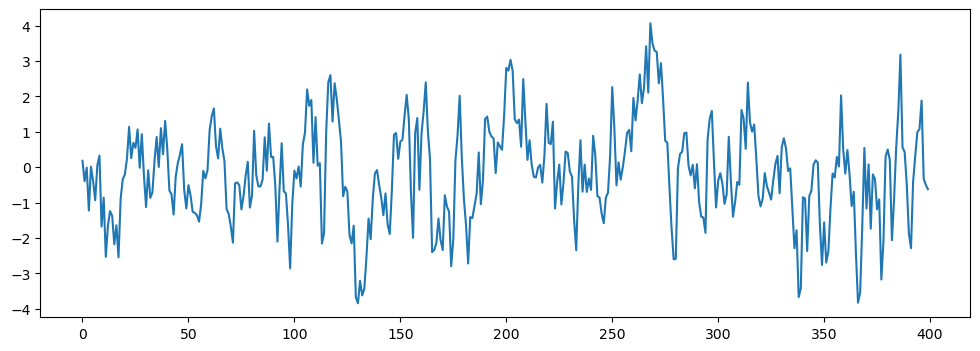

(-7.815492813068733,
 6.887979679449107e-12,
 0,
 399,
 {'1%': -3.446845912589748,
  '5%': -2.8688110853002007,
  '10%': -2.5706432834592747},
 1046.8247730523992)

In [3]:
# Example of stationary data -- AR(1)

X = sm.tsa.arma_generate_sample(ar=[1, -0.7], ma=[1], nsample=400)

fig, ax = plt.subplots(figsize = (12, 4))
ax.plot(X)
plt.show()

# We can run an augmented dicker-fuller test as follows
adf = sm.tsa.adfuller(X)
adf

# Here the p-value is very small (4.93e-11), so we can reject the null of nonstationarity and 
# proceed to model the series using ARMA

In [4]:
?sm.tsa.adfuller

Signature:
sm.tsa.adfuller(
    x,
    maxlag: 'int | None' = None,
    regression='c',
    autolag='AIC',
    store=False,
    regresults=False,
)
Docstring:
Augmented Dickey-Fuller unit root test.

The Augmented Dickey-Fuller test can be used to test for a unit root in a
univariate process in the presence of serial correlation.

Parameters
----------
x : array_like, 1d
    The data series to test.
maxlag : {None, int}
    Maximum lag which is included in test, default value of
    12*(nobs/100)^{1/4} is used when ``None``.
regression : {"c","ct","ctt","n"}
    Constant and trend order to include in regression.

    * "c" : constant only (default).
    * "ct" : constant and trend.
    * "ctt" : constant, and linear and quadratic trend.
    * "n" : no constant, no trend.

autolag : {"AIC", "BIC", "t-stat", None}
    Method to use when automatically determining the lag length among the
    values 0, 1, ..., maxlag.

    * If "AIC" (default) or "BIC", then the number of lags is chosen
  

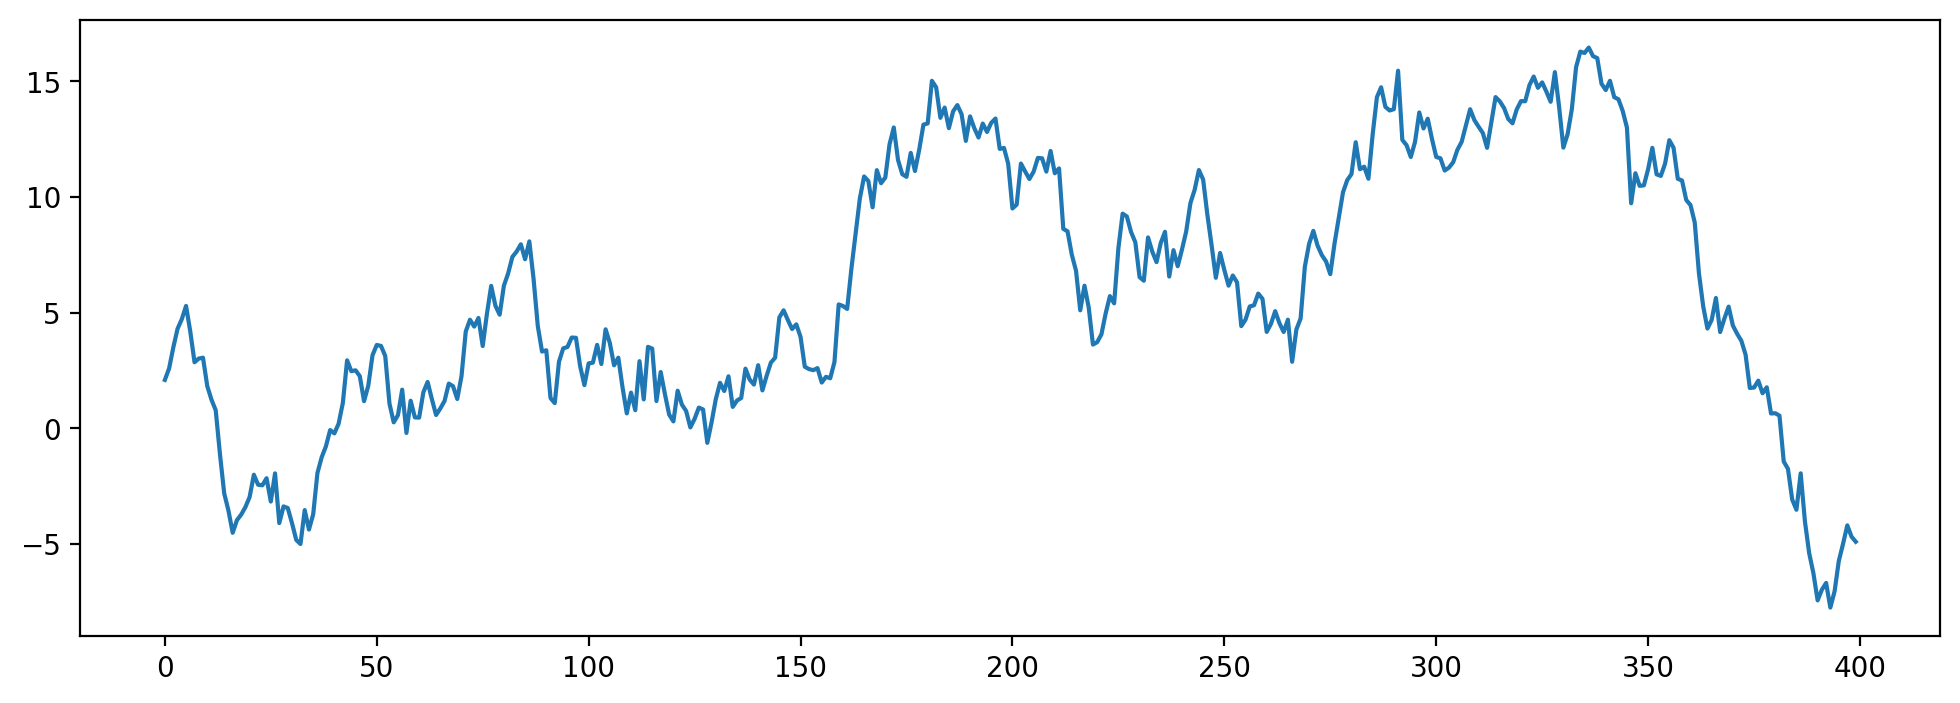

(-1.2368900554378133, 0.6575287198205859, 0, 399, {'1%': -3.446845912589748, '5%': -2.8688110853002007, '10%': -2.5706432834592747}, 1063.4686321622494)


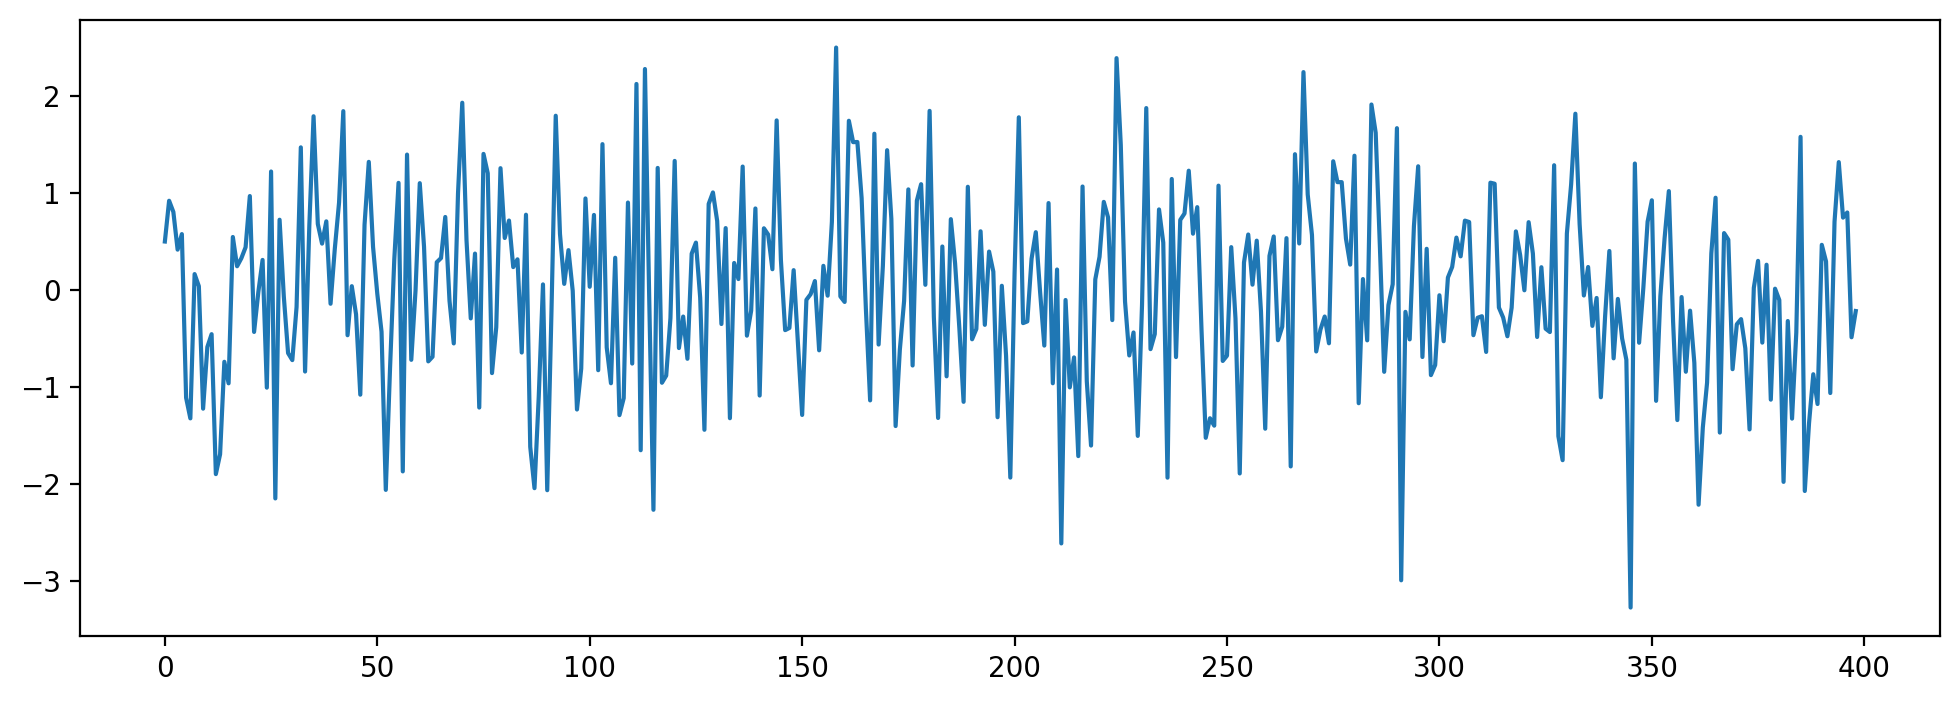

(-19.31509302413232, 0.0, 0, 398, {'1%': -3.4468876315017423, '5%': -2.868829424528516, '10%': -2.570653059771218}, 1064.1053462350355)


In [26]:
# Example of non-stationary data -- Random walk

Y = sm.tsa.arma_generate_sample(ar=[1, -1], ma=[1], nsample=400)
fig, ax = plt.subplots(figsize = (12, 4))
ax.plot(Y)
plt.show()

# Lets run our ADF test
adf = sm.tsa.adfuller(Y)
print(adf)

# Here our p value is 0.5855 -- we cannot reject the null of non-stationarity
# Lets difference our series
DeltaY = np.diff(Y, n=1)
fig, ax = plt.subplots(figsize = (12, 4))
ax.plot(DeltaY)
plt.show()

# That looks stationary now; lets check by running our test again
adf = sm.tsa.adfuller(DeltaY)
print(adf)
# p value of zero -- we can now reject the null of non-stationarity

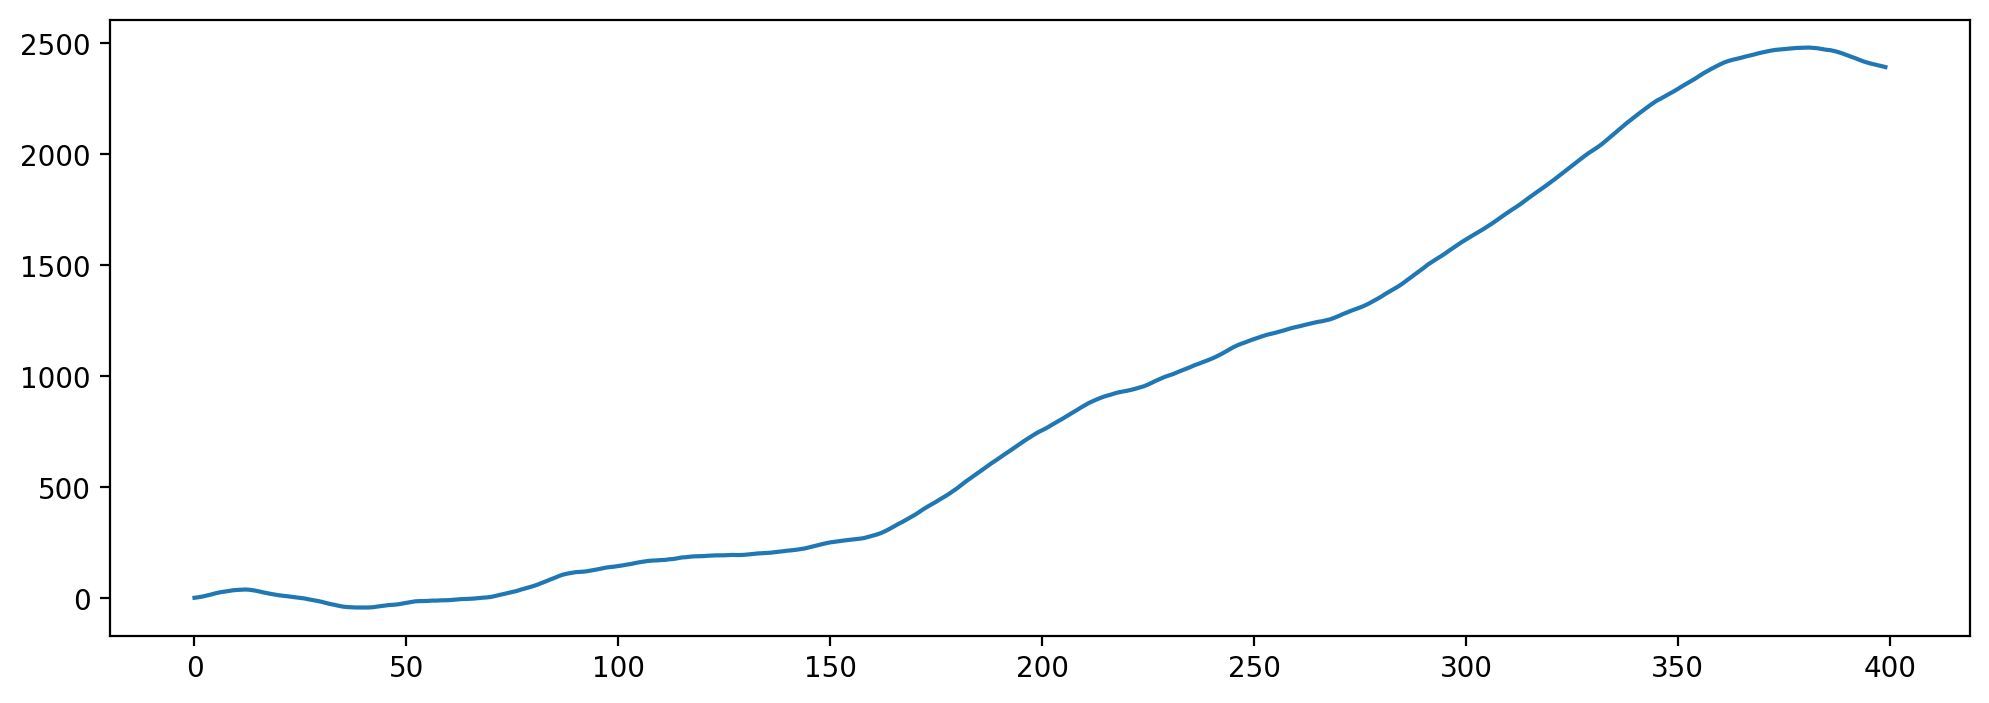

(-1.5992608202740453, 0.48396477587581144, 1, 398, {'1%': -3.4468876315017423, '5%': -2.868829424528516, '10%': -2.570653059771218}, 1061.8056138794068)


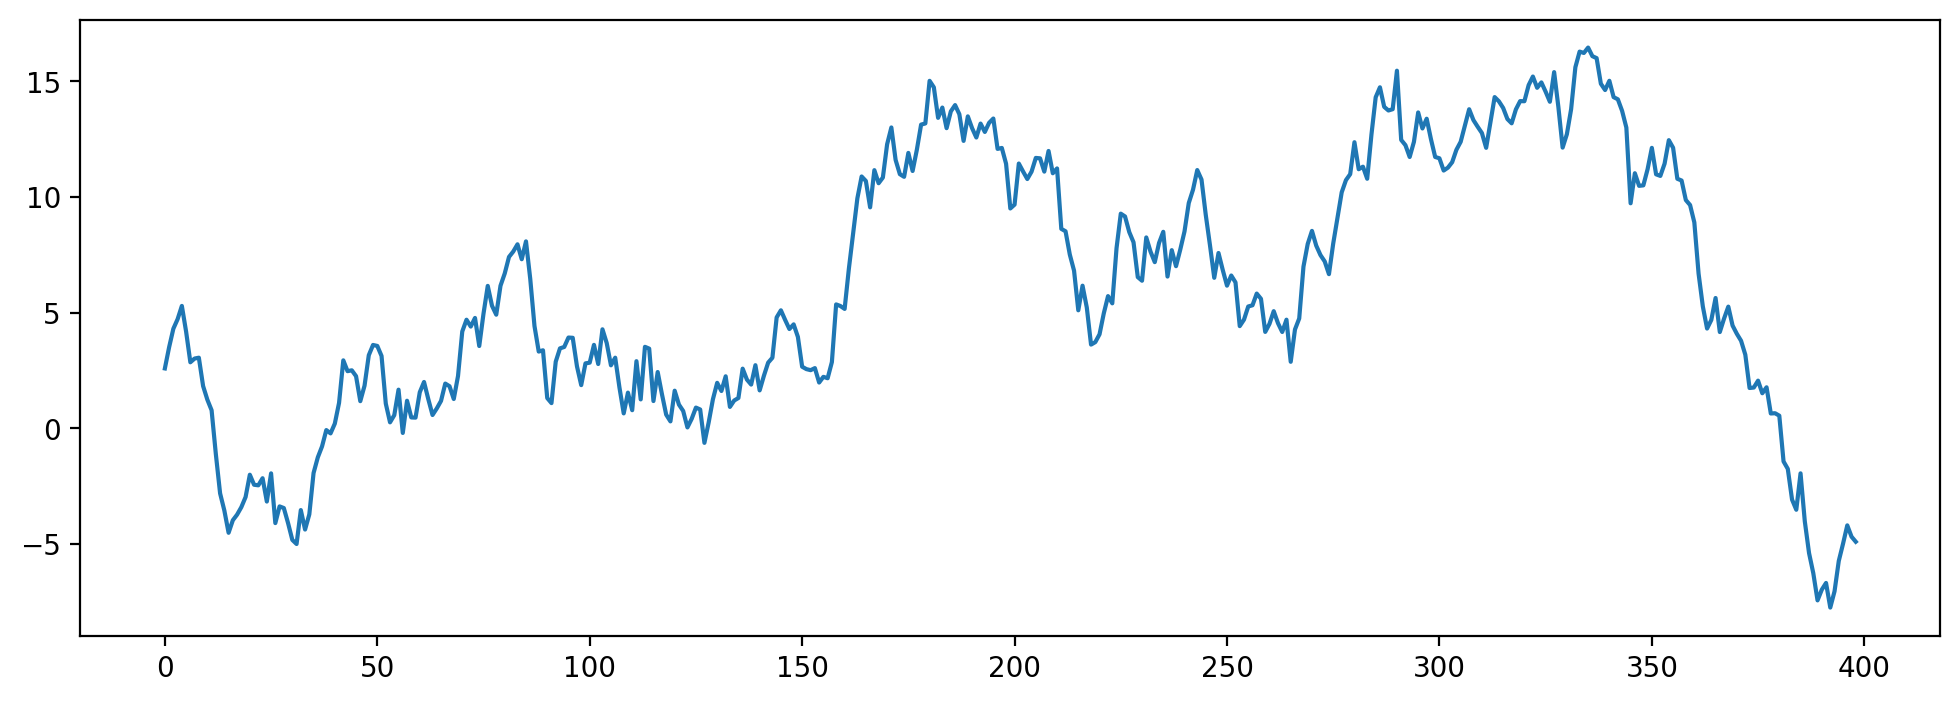

(-1.2180535984371248, 0.6657816958346043, 0, 398, {'1%': -3.4468876315017423, '5%': -2.868829424528516, '10%': -2.570653059771218}, 1061.682254714214)


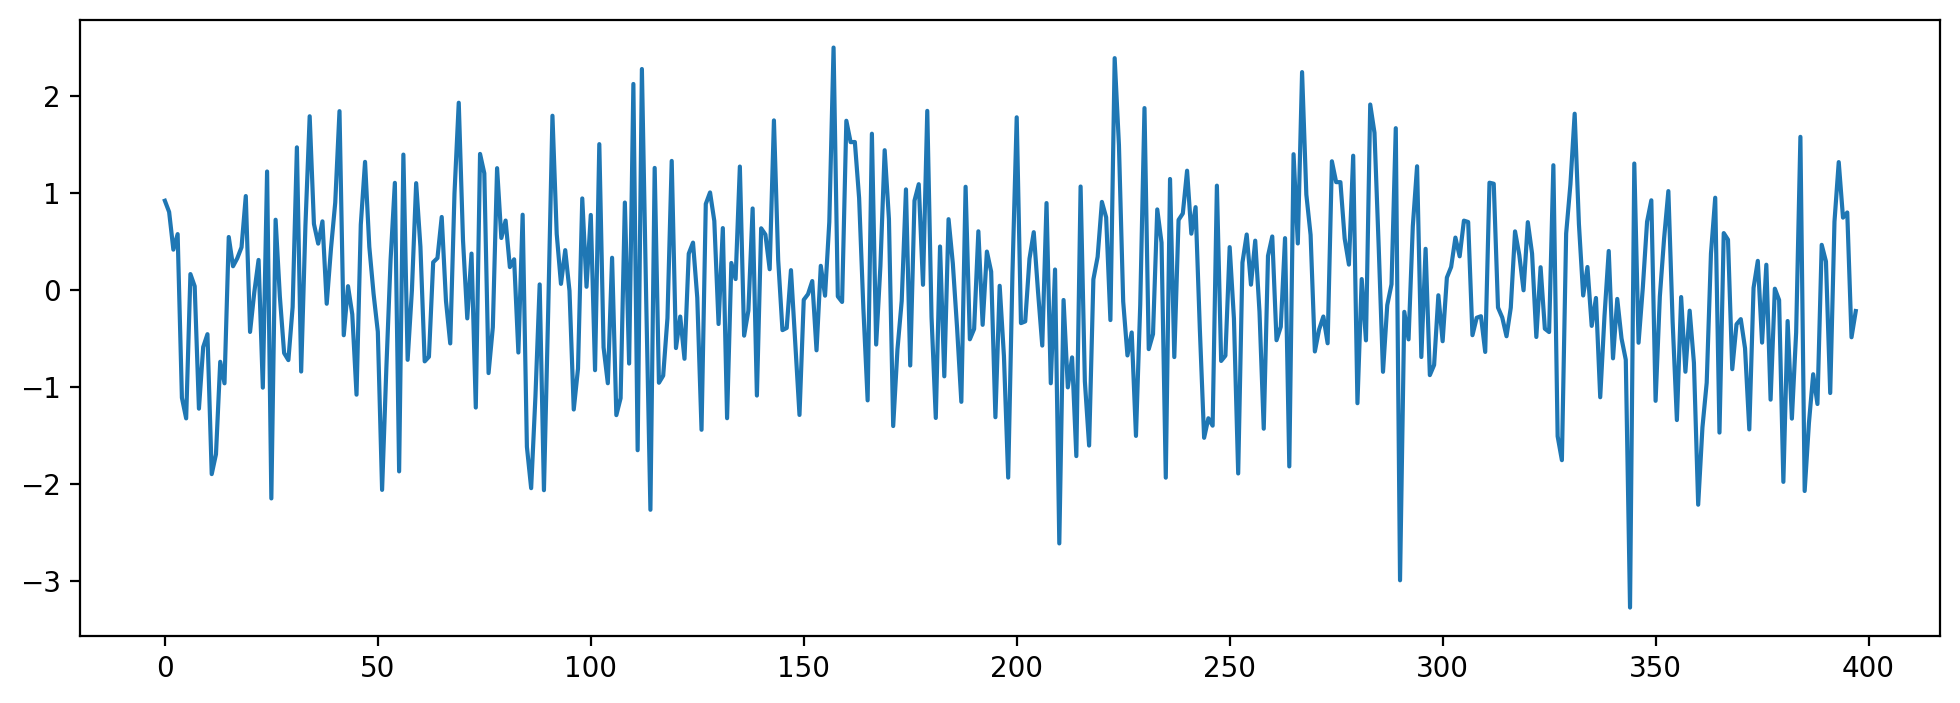

(-19.330902686626835, 0.0, 0, 397, {'1%': -3.4469295619737665, '5%': -2.8688478565083417, '10%': -2.570662885558566}, 1062.2094884745002)


In [30]:
# Example of process where twice differencing is required.

Z = np.cumsum(Y)
fig, ax = plt.subplots(figsize = (12, 4))
ax.plot(Z)
plt.show()

adf = sm.tsa.adfuller(Z)
print(adf)
# pvalue of 0.48... -- can't reject the null of nonstationarity

# Difference
DeltaZ = np.diff(Z, n=1)
fig, ax = plt.subplots(figsize = (12, 4))
ax.plot(DeltaZ)
plt.show()

# Still doesn't look stationary

adf = sm.tsa.adfuller(DeltaZ)
print(adf)
# pvalue of 0.66... -- can't reject the null of nonstationarity

# Difference again

DeltaSqZ = np.diff(DeltaZ, n=1)
# DeltaSqZ = np.diff(Z, n=2) # equivalent
fig, ax = plt.subplots(figsize = (12, 4))
ax.plot(DeltaSqZ)
plt.show()

# Still doesn't look stationary

adf = sm.tsa.adfuller(DeltaSqZ)
print(adf)
# pvalue of 0.0, we can now reject the null of nonstationarity. 
